In [1]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [2]:
df = pd.read_csv('adult.csv')

In [2]:
df = pd.read_csv('adult.csv', usecols=['age', 'capital.gain', 'capital.loss', 'hours.per.week', 'income'])

In [3]:
df.head()

,age,capital.gain,capital.loss,hours.per.week,income
0,90,0,4356,40,<=50K
1,82,0,4356,18,<=50K
2,66,0,4356,40,<=50K
3,54,0,3900,40,<=50K
4,41,0,3900,40,<=50K


In [4]:
df.isnull().sum()

age               0
capital.gain      0
capital.loss      0
hours.per.week    0
income            0
dtype: int64

In [5]:
x_train, x_test, y_train, y_test = train_test_split(
    df.drop(columns=['income']),
    df['income'],
    test_size= 0.4,
    random_state=42
)

Text(0.5, 1.0, 'Age QQ plot')

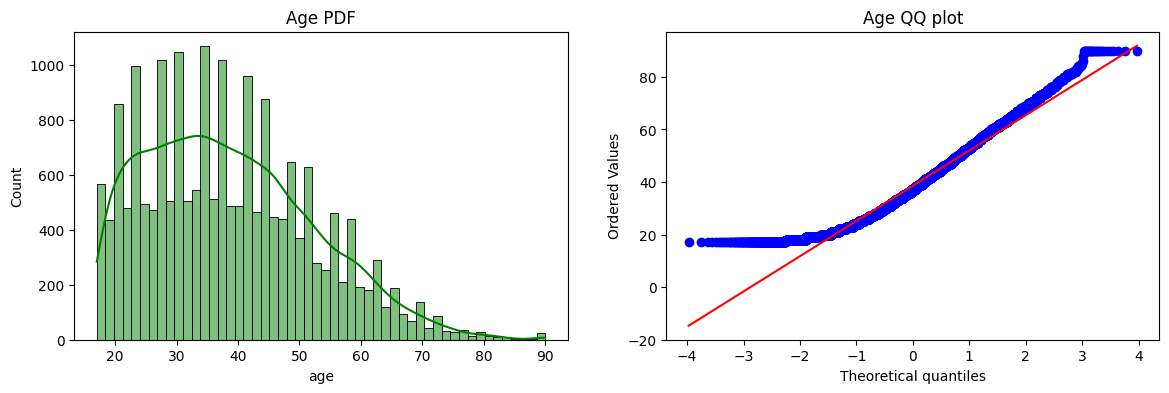

In [6]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(x_train['age'], kde=True, color='green')
plt.title('Age PDF')


plt.subplot(122)
stats.probplot(x_train['age'], dist='norm', plot=plt)
plt.title('Age QQ plot')

In [7]:
df.head(2)

,age,capital.gain,capital.loss,hours.per.week,income
0,90,0,4356,40,<=50K
1,82,0,4356,18,<=50K


Text(0.5, 1.0, 'Capital gain QQ plot')

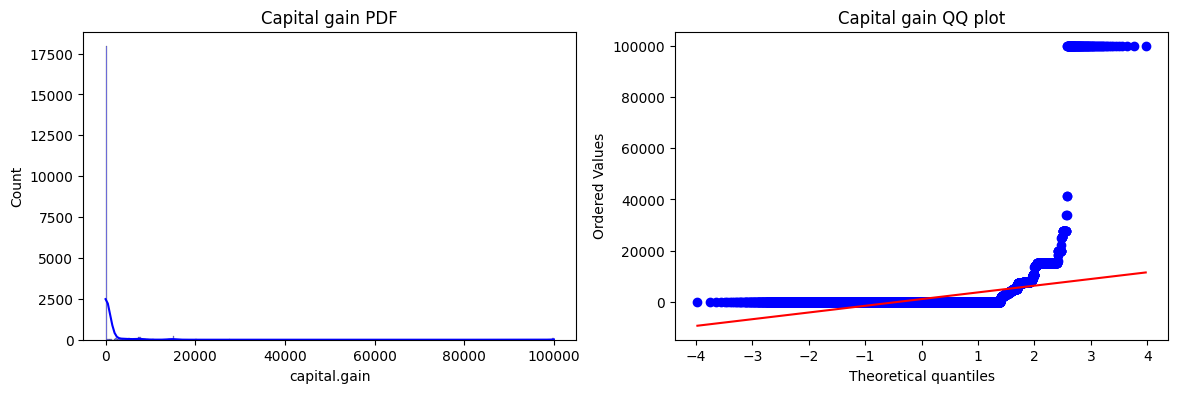

In [8]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(x_train['capital.gain'], kde=True, color='blue')
plt.title('Capital gain PDF')

plt.subplot(122)
stats.probplot(x_train['capital.gain'], dist='norm', plot=plt)
plt.title('Capital gain QQ plot')


In [9]:
df.head(2)

,age,capital.gain,capital.loss,hours.per.week,income
0,90,0,4356,40,<=50K
1,82,0,4356,18,<=50K


Text(0.5, 1.0, 'Capital loss QQ plot')

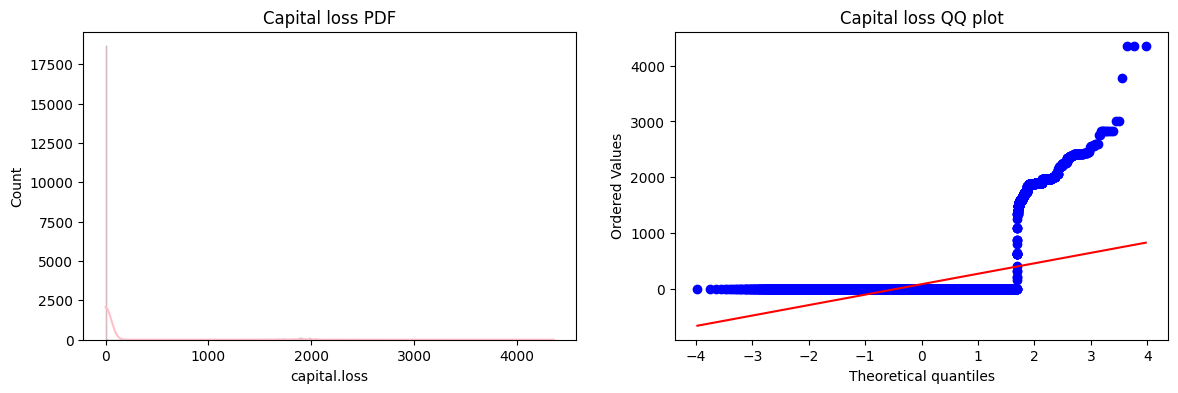

In [10]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(x_train['capital.loss'], kde=True, color='pink')
plt.title('Capital loss PDF')

plt.subplot(122)
stats.probplot(x_train['capital.loss'], dist='norm', plot=plt)
plt.title('Capital loss QQ plot')

In [11]:
df.head(2)

,age,capital.gain,capital.loss,hours.per.week,income
0,90,0,4356,40,<=50K
1,82,0,4356,18,<=50K


Text(0.5, 1.0, 'Hours QQ plot')

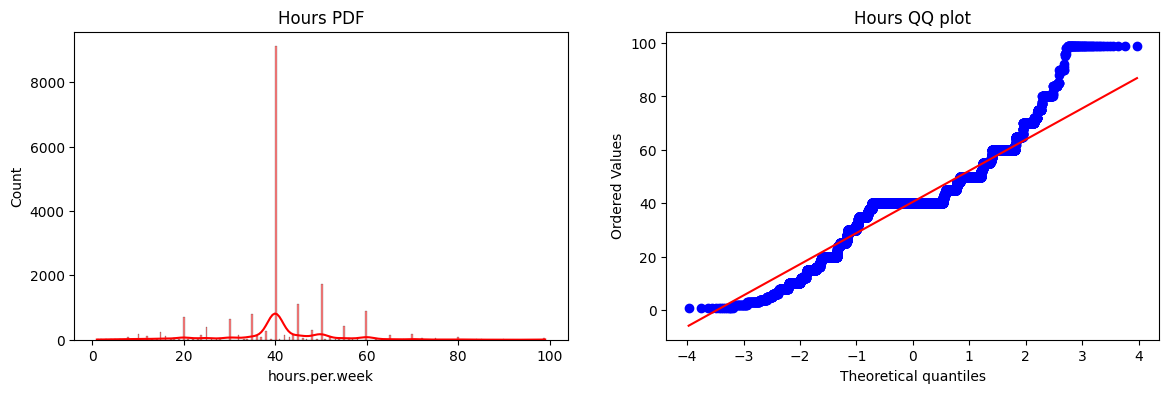

In [12]:
plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(x_train['hours.per.week'], kde=True, color='red')
plt.title('Hours PDF')

plt.subplot(122)
stats.probplot(x_train['hours.per.week'], dist='norm', plot=plt)
plt.title('Hours QQ plot')

In [13]:
# Accuracy before function transformer

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred = clf.predict(x_test)
y_pred1 = clf2.predict(x_test)

print('Accuracy of LR:', accuracy_score(y_test, y_pred))
print('Accuracy of DT', accuracy_score(y_test,y_pred))

Accuracy of LR: 0.7980038387715931
Accuracy of DT 0.7980038387715931


In [14]:
# Accuracy after Function transformer
trf = FunctionTransformer(func=np.log1p)

In [15]:
x_train_transformed = trf.fit_transform(x_train)
x_test_transformed = trf.transform(x_test)

In [16]:
df.head(2)

,age,capital.gain,capital.loss,hours.per.week,income
0,90,0,4356,40,<=50K
1,82,0,4356,18,<=50K


In [17]:
clf= LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(x_train_transformed,y_train)
clf2.fit(x_train_transformed,y_train)

y_pred = clf.predict(x_test_transformed)
y_pred2 = clf.predict(x_test_transformed)

print('Accuracy of LR:', accuracy_score(y_test,y_pred))
print('Accuracy of DT:', accuracy_score(y_test,y_pred2))



Accuracy of LR: 0.7892514395393474
Accuracy of DT: 0.7892514395393474


In [18]:
def my_func(transform):
    x = df.drop(columns=['income'])
    y = df['income']

    trf = ColumnTransformer([('trf', FunctionTransformer(transform),['capital.gain', 'capital.loss'])], remainder='passthrough')

    x_train = trf.fit_transform(x)

    clf = LogisticRegression()

    print('Accuracy:', np.mean(cross_val_score(clf, x_train,y,scoring='accuracy',cv=10)))

    plt.figure(figsize=(14,4))
    
    plt.subplot(121)
    stats.probplot(x['capital.gain'], dist='norm',plot=plt)
    plt.title("capital before Transform")

    plt.subplot(122)
    stats.probplot(x_train['capital.gain'], dist='norm',plot=plt)
    plt.title("capital gain after Transform")
    
   
    
    plt.subplot(123)
    stats.probplot(x['capital.loss'], dist='norm', plot=plt)
    plt.title("capital loss before Transform")

    plt.subplot(124)
    stats.probplot(x_train['capital.loss'], dist='norm', plot=plt)
    plt.title("capital loss after Transform")


    



Accuracy: 0.7497934141471139


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

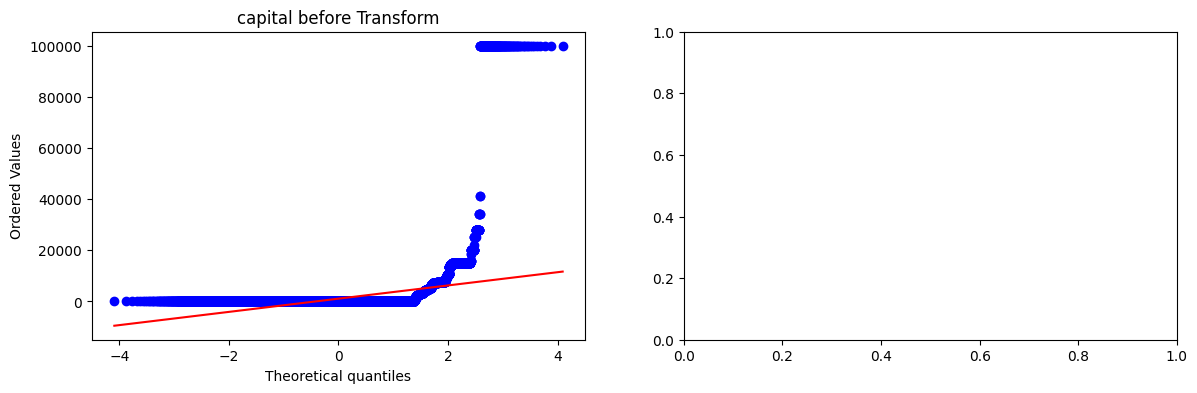

In [19]:
my_func(np.sin)